# 03 · Sensibilidade sintética de scores, sem rótulos

> Modelo reconstruído com `scale_pos_weight=13.882494684620836`; corte 0,50 apenas para observar mudanças de decisão.

**Pergunta.** O que acontece com a distribuição de scores se a utilização rotativa mudar gradualmente de **−50% a +50%, em passos de 5%**, na escala `log1p`, com ou sem propagação a dívida e idade? Este notebook usa `cs-test.csv`, com 101.503 linhas **sem Y**. Por isso **Brier, AUC ROC, PR-AUC trapezoidal, KS do modelo, recall e precisão são indisponíveis**. A saída é uma análise de sensibilidade das previsões, não desempenho observado.

**Etapas para reutilizar:** (1) congelar modelo e amostra sem rótulos; (2) escolher uma variável motora e escala apropriada; (3) especificar percentuais, direções e limite de suporte; (4) estimar dependência com outras entradas sem usar Y; (5) transformar X, prever de novo e medir PSI, Wasserstein, score médio e cruzamentos do corte; (6) auditar clipping, faixas e correlações. Mudanças sintéticas de X não autorizam manter Y antigo como verdade contrafactual.

In [1]:
from pathlib import Path

# Resolve o projeto tanto pelo Jupyter aberto em notebooks/ quanto pelo executor.
_inicio = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (_inicio, *_inicio.parents)
     if (p / "models" / "manifesto_modelo.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Não encontrei models/manifesto_modelo.json. Abra o projeto clonado.")
DATA_DIR_PROJECT = PROJECT_ROOT / "data" / "raw"
MODEL_DIR = PROJECT_ROOT / "models"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
for _nome in ("cs-training.csv", "cs-test.csv"):
    if not (DATA_DIR_PROJECT / _nome).is_file():
        raise FileNotFoundError(
            f"Falta {DATA_DIR_PROJECT / _nome}. Veja README.md, seção Dados."
        )


In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm, wasserstein_distance
import xgboost as xgb
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
np.set_printoptions(precision=4, suppress=True)

P = DATA_DIR_PROJECT
DATA_DIR = next((d for d in (P, P.parent) if (d / "cs-test.csv").is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Coloque os CSVs em data/raw/ e execute a partir da raiz do projeto ou de notebooks/.")
OUT_DIR = TABLES_DIR
DATA_PATH = DATA_DIR / "cs-test.csv"
MODEL_PATH = MODEL_DIR / 'model_class_retreinado.json'
MANIFEST_PATH = MODEL_DIR / 'manifesto_modelo.json'
assert DATA_PATH.exists() and MODEL_PATH.exists() and MANIFEST_PATH.exists(), "Verifique os caminhos de dados e modelo."

manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
FEATURES = manifest["features"]
R = "RevolvingUtilizationOfUnsecuredLines"
D = "DebtRatio"
A = "age"
CUTOFF = float(manifest["cutoff"])
raw = pd.read_csv(DATA_PATH)
assert raw["SeriousDlqin2yrs"].isna().all(), "O teste deveria estar sem rótulos; revise antes de usar este caderno."
X0 = raw.loc[:, FEATURES].copy()
assert X0[[R, D, A]].notna().all().all(), "As três variáveis do cenário precisam estar completas."
assert np.isfinite(X0[[R, D, A]].to_numpy(dtype=float)).all()
assert (X0[[R, D, A]] >= 0).all().all()

booster = xgb.Booster()
booster.load_model(str(MODEL_PATH))
booster.set_param({"device": "cpu", "nthread": 4})
assert booster.feature_names == FEATURES
def predict_score(X):
    return booster.predict(xgb.DMatrix(X.loc[:, FEATURES], feature_names=FEATURES))

p0 = predict_score(X0)
print(f"Teste: {len(X0):,} linhas | rótulos observados: {raw['SeriousDlqin2yrs'].notna().sum():,}")
print(f"Modelo: {booster.num_boosted_rounds()} rodadas | {len(FEATURES)} variáveis | corte fixo: {CUTOFF:g}")
print(f"Score base médio: {p0.mean():.4f} | decisões positivas: {(p0 >= CUTOFF).mean():.2%}")
print("Status do artefato:", manifest["status"])
display(X0[[R, D, A]].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T)

Teste: 101,503 linhas | rótulos observados: 0
Modelo: 103 rodadas | 10 variáveis | corte fixo: 0.5
Score base médio: 0.3224 | decisões positivas: 24.20%
Status do artefato: retreino com scale_pos_weight=13.882494684620836; nao e o Booster original


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
RevolvingUtilizationOfUnsecuredLines,101503.0,5.310000,196.156039,0.0,0.0,0.000000,0.030131,0.152586,0.564225,1.0,1.08869,21821.0
DebtRatio,101503.0,344.475020,1632.595231,0.0,0.0,0.004383,0.173423,0.364260,0.851619,2435.0,4963.00000,268326.0
age,101503.0,52.405436,14.779756,21.0,24.0,29.000000,41.000000,52.000000,63.000000,78.0,87.00000,104.0


In [3]:
# Verifica que o modelo, o manifesto e a configuração deste estudo coincidem.
import hashlib as _hashlib
import json as _json
_manifesto_versao = _json.loads(
    (MODEL_DIR / "manifesto_modelo.json").read_text(encoding="utf-8")
)
assert abs(_manifesto_versao["params_fornecidos"]["scale_pos_weight"]
           - 13.882494684620836) < 1e-12
assert _manifesto_versao["cutoff"] == 0.5
assert _manifesto_versao["features"] == FEATURES
_arquivo_modelo_versao = MODEL_DIR / "model_class_retreinado.json"
assert _hashlib.sha256(_arquivo_modelo_versao.read_bytes()).hexdigest() == \
       _manifesto_versao["model_sha256"], "Booster e manifesto divergentes."
print("Modelo validado:", _manifesto_versao["variant"])


Modelo validado: metricas_brier_auc_prauc_ks_grade_5a50


## Construção e interpretação dos parâmetros

1. **Motor univariado:** $u=\log(1+r)$ para utilização $r$. Aplicamos $u'=\min\{u(1+s\delta),\log(1+r_{\max})\}$, com $s=-1$ ou $+1$ e $\delta\in\{0,0{,}05,\ldots,0{,}50\}$. Assim, o aumento/redução é de 5% em 5% **na escala transformada u**, não necessariamente no valor bruto r. Depois, $r'=\exp(u')-1$. Zeros continuam zeros; o clipping superior é contado.
2. **Propagação:** mapeamos utilização, dívida e idade para postos gaussianos $z=\Phi^{-1}(\widehat F(x))$. Para $j$ em dívida/idade, $z'_j=z_j+lphaho_{jr}(z'_r-z_r)$ e voltamos pela quantil empírica. $lpha=0$ isola o motor; 0,5 propaga metade; 1 propaga integralmente sob a aproximação gaussiana. $ho_{jr}$ é correlação de postos no arquivo base, não causalidade.
3. **Medição:** PSI usa bins fixados no arquivo base; Wasserstein/IQR mede distância na escala indicada. Também reportamos mudança média/absoluta do score, participação acima de 0,50 e registros que cruzam o corte. Essas medidas não são acurácia.

In [4]:
# Diagnóstico da dependência usada para propagar o cenário.
TRIO = [R, D, A]
n = len(X0)
sorted_ref = {c: np.sort(X0[c].to_numpy(dtype=float)) for c in TRIO}

def normal_score(values, reference_sorted):
    # Posto médio contra a referência, com limites que evitam Phi^-1(0/1).
    v = np.asarray(values, dtype=float)
    left = np.searchsorted(reference_sorted, v, side="left")
    right = np.searchsorted(reference_sorted, v, side="right")
    u = (0.5 * (left + right) + 0.5) / (len(reference_sorted) + 1.0)
    return norm.ppf(np.clip(u, 1/(len(reference_sorted)+1), len(reference_sorted)/(len(reference_sorted)+1)))

def empirical_quantile(z, reference_sorted):
    # Quantil da referência; usar observação próxima mantém idade inteira.
    u = norm.cdf(z)
    # Inversa discreta da mesma CDF usada em normal_score. Assim, sem
    # deslocamento latente, inclusive valores máximos voltam a si próprios.
    idx = np.ceil(np.clip(u, 0, 1) * (len(reference_sorted) + 1) - 1e-10).astype(int) - 1
    idx = np.clip(idx, 0, len(reference_sorted) - 1)
    return reference_sorted[idx]

z_ref = {c: normal_score(X0[c].to_numpy(dtype=float), sorted_ref[c]) for c in TRIO}
for c in [D, A]:
    assert np.array_equal(empirical_quantile(z_ref[c], sorted_ref[c]), X0[c].to_numpy(dtype=float))
rho = {c: float(np.corrcoef(z_ref[R], z_ref[c])[0, 1]) for c in [D, A]}
print("Correlação de postos gaussianos com o motor:", rho)
print("Correlação Spearman observada:")
display(X0[TRIO].corr(method="spearman").round(3))

Correlação de postos gaussianos com o motor: {'DebtRatio': 0.0677892605779981, 'age': -0.26746841267975685}
Correlação Spearman observada:


,RevolvingUtilizationOfUnsecuredLines,DebtRatio,age
RevolvingUtilizationOfUnsecuredLines,1.000,0.078,-0.280
DebtRatio,0.078,1.000,0.025
age,-0.280,0.025,1.000


In [5]:
def scenario(direction, intensity, propagation):
    # Uma transformação determinística nas mesmas linhas, sem tocar nos rótulos.
    X = X0.copy()
    r = X0[R].to_numpy(dtype=float)
    log_r = np.log1p(r)
    log_max = np.log1p(sorted_ref[R][-1])
    scaled = log_r * (1 + direction * intensity)
    r_new = np.clip(np.expm1(np.minimum(scaled, log_max)), 0, sorted_ref[R][-1])
    X[R] = r_new
    dz = normal_score(r_new, sorted_ref[R]) - z_ref[R]
    if propagation:
        for c in [D, A]:
            z_new = z_ref[c] + propagation * rho[c] * dz
            X[c] = empirical_quantile(z_new, sorted_ref[c])
    clipping = float(np.mean(scaled > log_max))
    return X, clipping

def psi_fixed(ref, changed):
    # PSI descritivo, 10 quantis de referência (empates colapsados).
    cuts = np.unique(np.quantile(ref, np.linspace(.1, .9, 9)))
    edges = np.r_[-np.inf, cuts, np.inf]
    c0 = np.histogram(ref, bins=edges)[0].astype(float)
    c1 = np.histogram(changed, bins=edges)[0].astype(float)
    eps = 1e-6
    p = (c0 + eps) / (c0.sum() + eps*len(c0))
    q = (c1 + eps) / (c1.sum() + eps*len(c1))
    return float(np.sum((q-p) * np.log(q/p)))

def scaled_w1(ref, changed, log_scale=False):
    r = np.log1p(ref) if log_scale else ref
    c = np.log1p(changed) if log_scale else changed
    spread = np.quantile(r, .75) - np.quantile(r, .25)
    return float(wasserstein_distance(r, c) / max(spread, 1e-12))

def evaluate(direction, intensity, propagation):
    X, clipping = scenario(direction, intensity, propagation)
    p = predict_score(X)
    d0, d1 = p0 >= CUTOFF, p >= CUTOFF
    # Nenhuma variável fora do cenário muda; nenhum NaN é introduzido.
    assert X.drop(columns=TRIO).equals(X0.drop(columns=TRIO))
    assert X.isna().equals(X0.isna())
    assert (X[TRIO] >= X0[TRIO].min()).all().all()
    assert (X[TRIO] <= X0[TRIO].max()).all().all()
    assert np.all(X[A] == np.floor(X[A]))
    base_positive = X0[R].to_numpy(dtype=float) > 0
    raw_change_pct = 100 * (X[R].to_numpy(dtype=float)[base_positive] /
                            X0[R].to_numpy(dtype=float)[base_positive] - 1)
    corr_new = X[TRIO].corr(method="spearman")
    corr_base = X0[TRIO].corr(method="spearman")
    off_diag = ~np.eye(3, dtype=bool)
    return {
        "direcao": "aumento" if direction == 1 else "reducao",
        "sinal": direction,
        "intensidade": intensity,
        "propagacao": propagation,
        "PSI_utilizacao": psi_fixed(X0[R], X[R]),
        "mudanca_bruta_media_pct_positivos": float(raw_change_pct.mean()),
        "mudanca_bruta_mediana_pct_positivos": float(np.median(raw_change_pct)),
        "PSI_divida": psi_fixed(X0[D], X[D]),
        "PSI_idade": psi_fixed(X0[A], X[A]),
        "W1log_utilizacao_IQR": scaled_w1(X0[R], X[R], log_scale=True),
        "W1log_divida_IQR": scaled_w1(X0[D], X[D], log_scale=True),
        "W1_idade_IQR": scaled_w1(X0[A], X[A]),
        "delta_score_medio_pp": float((p-p0).mean()*100),
        "mudanca_absoluta_score_pp": float(np.abs(p-p0).mean()*100),
        "P95_mudanca_abs_score_pp": float(np.quantile(np.abs(p-p0),.95)*100),
        "positivos_pct": float(d1.mean()*100),
        "cruzaram_corte_pct": float((d0 != d1).mean()*100),
        "cruzaram_para_positivo_pct": float((~d0 & d1).mean()*100),
        "cruzaram_para_negativo_pct": float((d0 & ~d1).mean()*100),
        "clipping_superior_pct": clipping*100,
        "maior_mudanca_corr_spearman": float(np.abs((corr_new-corr_base).to_numpy()[off_diag]).max()),
    }

scenarios = [evaluate(s, lam, alpha)
             for s in [-1, 1] for lam in np.round(np.arange(0, .501, .05), 2) for alpha in [0, .5, 1]]
results = pd.DataFrame(scenarios).sort_values(["direcao", "intensidade", "propagacao"])
results.to_csv(OUT_DIR / "resultados_sinteticos.csv", index=False, encoding="utf-8-sig")
print(f"Cenários executados: {len(results)} | base: {len(X0):,} linhas | corte {CUTOFF:g}")
display(results[["direcao", "intensidade", "propagacao", "PSI_utilizacao", "PSI_divida", "PSI_idade",
                 "mudanca_bruta_media_pct_positivos", "mudanca_bruta_mediana_pct_positivos",
                 "delta_score_medio_pp", "mudanca_absoluta_score_pp", "P95_mudanca_abs_score_pp",
                 "positivos_pct", "cruzaram_corte_pct", "clipping_superior_pct"]].round(3))
print("Distância Wasserstein normalizada pelo IQR da referência:")
display(results[["direcao", "intensidade", "propagacao", "W1log_utilizacao_IQR", "W1log_divida_IQR", "W1_idade_IQR"]].round(3))

Cenários executados: 66 | base: 101,503 linhas | corte 0.5


,direcao,intensidade,propagacao,PSI_utilizacao,PSI_divida,PSI_idade,mudanca_bruta_media_pct_positivos,mudanca_bruta_mediana_pct_positivos,delta_score_medio_pp,mudanca_absoluta_score_pp,P95_mudanca_abs_score_pp,positivos_pct,cruzaram_corte_pct,clipping_superior_pct
33,aumento,0.00,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,24.195,0.000,0.000
34,aumento,0.00,0.5,0.000,0.000,0.000,0.000,0.000,-0.014,0.018,0.000,24.173,0.031,0.000
35,aumento,0.00,1.0,0.000,0.000,0.000,0.000,0.000,-0.021,0.032,0.000,24.146,0.061,0.000
36,aumento,0.05,0.0,0.009,0.000,0.000,5.825,5.472,1.111,1.126,7.580,25.990,1.811,0.004
37,aumento,0.05,0.5,0.009,0.000,0.000,5.825,5.472,1.171,1.190,7.987,26.126,1.947,0.004
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28,reducao,0.45,0.5,0.864,0.000,0.003,-48.376,-47.159,-5.623,5.659,20.139,15.204,9.009,0.000
29,reducao,0.45,1.0,0.864,0.001,0.009,-48.376,-47.159,-5.852,5.899,20.898,15.010,9.201,0.000
30,reducao,0.50,0.0,1.273,0.000,0.000,-53.376,-52.175,-5.893,5.922,21.350,14.917,9.296,0.000
31,reducao,0.50,0.5,1.273,0.000,0.004,-53.376,-52.175,-6.169,6.205,22.083,14.663,9.554,0.000


Distância Wasserstein normalizada pelo IQR da referência:


,direcao,intensidade,propagacao,W1log_utilizacao_IQR,W1log_divida_IQR,W1_idade_IQR
33,aumento,0.00,0.0,0.000,0.000,0.000
34,aumento,0.00,0.5,0.000,0.003,0.002
35,aumento,0.00,1.0,0.000,0.006,0.003
36,aumento,0.05,0.0,0.031,0.000,0.000
37,aumento,0.05,0.5,0.031,0.016,0.006
...,...,...,...,...,...,...
28,reducao,0.45,0.5,0.277,0.050,0.033
29,reducao,0.45,1.0,0.277,0.100,0.063
30,reducao,0.50,0.0,0.308,0.000,0.000
31,reducao,0.50,0.5,0.308,0.056,0.039


## Leitura dos resultados

`intensidade` é percentual **nominal** aplicado na escala log(1+r), em passos de 5%; `mudanca_bruta_*_pct_positivos` mede o percentual efetivamente realizado em valores brutos originalmente positivos após a transformação e o clipping. Zeros permanecem zero e não entram no quociente. `PSI` e `W1/IQR` medem a alteração das **entradas**. `delta_score_medio_pp` usa sinal: a média dos scores subiu ou caiu em pontos percentuais. `mudanca_absoluta_score_pp` capta mudanças que se cancelariam na média. `cruzaram_corte_pct` conta clientes cuja decisão em 0,5 mudou em qualquer direção, mantendo os mesmos registros nas duas avaliações. Ele não indica erro ou acerto, pois faltam os desfechos reais.

A distinção entre $\alpha=0$ e $\alpha>0$ compara um choque só na utilização com um cenário em que dívida e idade acompanham parte da mudança. Não se deve somar os PSI das variáveis para obter um PSI multivariado.

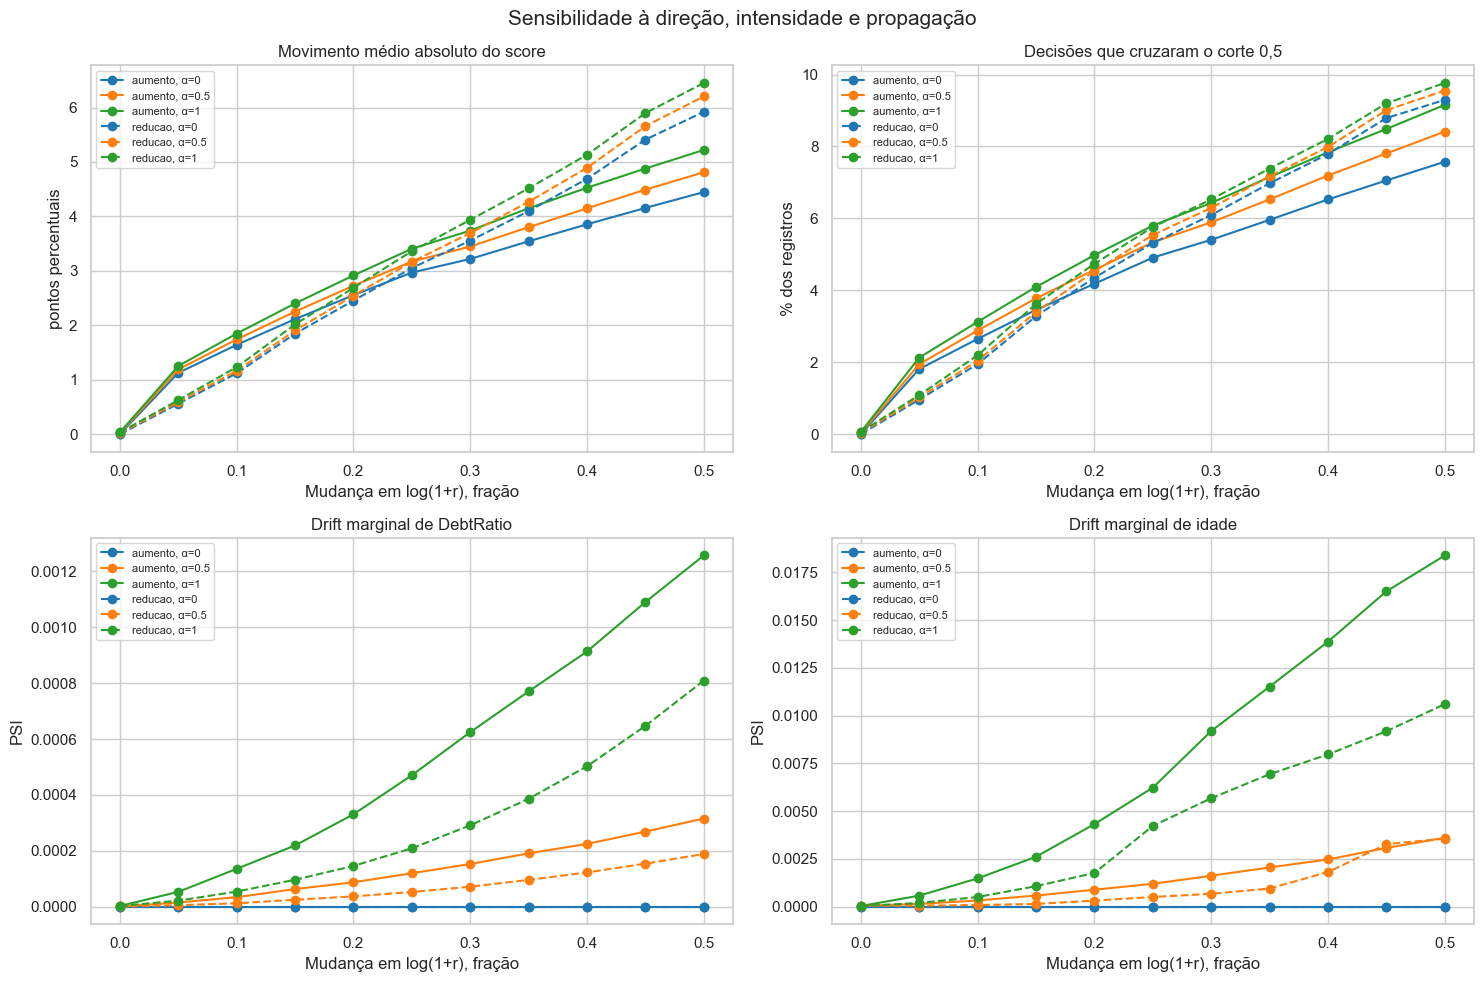

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
pal = {0.0: "#1f77b4", 0.5: "#ff7f0e", 1.0: "#2ca02c"}
styles = {"reducao": "--", "aumento": "-"}
for (name, g) in results.groupby(["direcao", "propagacao"], sort=True):
    direction, alpha = name
    g = g.sort_values("intensidade")
    label = f"{direction}, α={alpha:g}"
    axes[0,0].plot(g["intensidade"], g["mudanca_absoluta_score_pp"], marker="o", color=pal[alpha], ls=styles[direction], label=label)
    axes[0,1].plot(g["intensidade"], g["cruzaram_corte_pct"], marker="o", color=pal[alpha], ls=styles[direction], label=label)
    axes[1,0].plot(g["intensidade"], g["PSI_divida"], marker="o", color=pal[alpha], ls=styles[direction], label=label)
    axes[1,1].plot(g["intensidade"], g["PSI_idade"], marker="o", color=pal[alpha], ls=styles[direction], label=label)
for ax, title, ylabel in zip(axes.ravel(),
    ["Movimento médio absoluto do score", "Decisões que cruzaram o corte 0,5", "Drift marginal de DebtRatio", "Drift marginal de idade"],
    ["pontos percentuais", "% dos registros", "PSI", "PSI"]):
    ax.set(title=title, xlabel="Mudança em log(1+r), fração", ylabel=ylabel)
    ax.set_xticks(np.arange(0,.51,.1))
    ax.legend(fontsize=8)
fig.suptitle("Sensibilidade à direção, intensidade e propagação", fontsize=15)
fig.tight_layout()
plt.show()

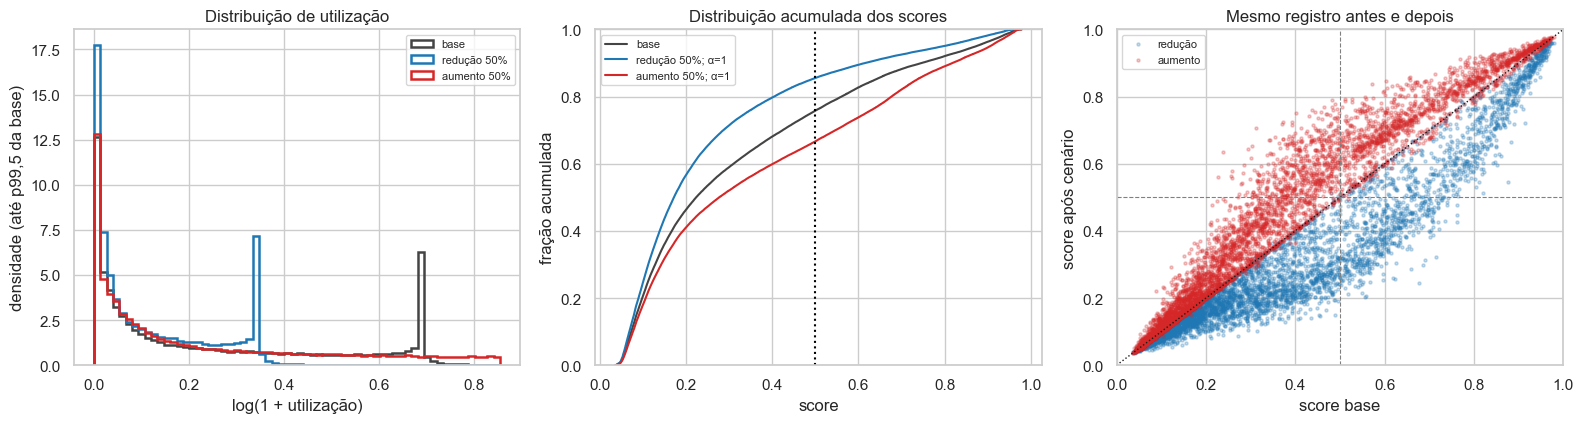

In [7]:
# Casos extremos para inspecionar deslocamento de entradas e scores.
X_down, clip_down = scenario(-1, .5, 1)
X_up, clip_up = scenario(1, .5, 1)
p_down, p_up = predict_score(X_down), predict_score(X_up)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
bins = np.linspace(0, np.quantile(np.log1p(X0[R]), .995), 65)
for values, lab, col in [(X0[R], "base", "#444444"), (X_down[R], "redução 50%", "#1f77b4"), (X_up[R], "aumento 50%", "#d62728")]:
    axes[0].hist(np.log1p(values), bins=bins, histtype="step", density=True, linewidth=1.8, label=lab, color=col)
axes[0].set(title="Distribuição de utilização", xlabel="log(1 + utilização)", ylabel="densidade (até p99,5 da base)")
axes[0].legend(fontsize=8)
for values, lab, col in [(p0, "base", "#444444"), (p_down, "redução 50%; α=1", "#1f77b4"), (p_up, "aumento 50%; α=1", "#d62728")]:
    sns.ecdfplot(values, ax=axes[1], label=lab, color=col)
axes[1].axvline(CUTOFF, color="black", ls=":")
axes[1].set(title="Distribuição acumulada dos scores", xlabel="score", ylabel="fração acumulada")
axes[1].legend(fontsize=8)
rng = np.random.default_rng(33)
idx = rng.choice(len(X0), 6000, replace=False)
axes[2].scatter(p0[idx], p_down[idx], s=5, alpha=.25, color="#1f77b4", label="redução")
axes[2].scatter(p0[idx], p_up[idx], s=5, alpha=.25, color="#d62728", label="aumento")
axes[2].plot([0,1], [0,1], "k:", linewidth=1)
axes[2].axvline(CUTOFF, color="gray", ls="--", linewidth=.8)
axes[2].axhline(CUTOFF, color="gray", ls="--", linewidth=.8)
axes[2].set(xlim=(0,1), ylim=(0,1), title="Mesmo registro antes e depois", xlabel="score base", ylabel="score após cenário")
axes[2].legend(fontsize=8)
fig.tight_layout()
plt.show()

In [8]:
# Checagens de validade das variáveis e da dependência entre elas.
checks = []
for lab, X, clip in [("base", X0, 0.0), ("redução forte, α=1", X_down, clip_down), ("aumento forte, α=1", X_up, clip_up)]:
    checks.append({
        "cenario": lab,
        "utilizacao_min": X[R].min(), "utilizacao_max": X[R].max(),
        "divida_min": X[D].min(), "divida_max": X[D].max(),
        "idade_min": X[A].min(), "idade_max": X[A].max(),
        "idade_nao_inteira": int((X[A] != np.floor(X[A])).sum()),
        "faltantes_trio": int(X[TRIO].isna().sum().sum()),
        "clipping_superior_pct": clip*100,
        "corr_utilizacao_idade": X[TRIO].corr(method="spearman").loc[R,A],
        "corr_utilizacao_divida": X[TRIO].corr(method="spearman").loc[R,D],
    })
display(pd.DataFrame(checks).round(3))

for direction in ["reducao", "aumento"]:
    g = results.query("direcao == @direction and intensidade == 0.5").set_index("propagacao")
    univ, multi = g.loc[0.0], g.loc[1.0]
    print(f"{direction.capitalize()} 50% em log1p: choque univariado move o score {univ['mudanca_absoluta_score_pp']:.2f} pp em média e troca {univ['cruzaram_corte_pct']:.2f}% das decisões.")
    print(f" Com propagação total: {multi['mudanca_absoluta_score_pp']:.2f} pp e {multi['cruzaram_corte_pct']:.2f}%; PSI da dívida {multi['PSI_divida']:.3f}, da idade {multi['PSI_idade']:.3f}.")

display(Markdown('**Conclusão restrita deste caderno.** Os gráficos mostram a sensibilidade de score e de decisões dentro dos 66 cenários definidos. Não definem um nível máximo *suportado* de drift em termos de risco de crédito ou qualidade preditiva: isso exige rótulos observados e critérios de negócio (com métricas supervisionadas e validação temporal). Para drift de população mantendo pares $(X,Y)$ válidos, use os ensaios de reponderação no holdout rotulado dos outros cadernos.'))

,cenario,utilizacao_min,utilizacao_max,divida_min,divida_max,idade_min,idade_max,idade_nao_inteira,faltantes_trio,clipping_superior_pct,corr_utilizacao_idade,corr_utilizacao_divida
0,base,0.0,21821.000,0.0,268326.0,21.0,104.0,0,0,0.000,-0.280,0.078
1,"redução forte, α=1",0.0,146.723,0.0,268326.0,21.0,104.0,0,0,0.000,-0.213,0.062
2,"aumento forte, α=1",0.0,21821.000,0.0,268326.0,21.0,101.0,0,0,0.111,-0.374,0.104


Reducao 50% em log1p: choque univariado move o score 5.92 pp em média e troca 9.30% das decisões.
 Com propagação total: 6.45 pp e 9.77%; PSI da dívida 0.001, da idade 0.011.
Aumento 50% em log1p: choque univariado move o score 4.45 pp em média e troca 7.58% das decisões.
 Com propagação total: 5.22 pp e 9.16%; PSI da dívida 0.001, da idade 0.018.


**Conclusão restrita deste caderno.** Os gráficos mostram a sensibilidade de score e de decisões dentro dos 66 cenários definidos. Não definem um nível máximo *suportado* de drift em termos de risco de crédito ou qualidade preditiva: isso exige rótulos observados e critérios de negócio (com métricas supervisionadas e validação temporal). Para drift de população mantendo pares $(X,Y)$ válidos, use os ensaios de reponderação no holdout rotulado dos outros cadernos.

### Limites e reprodução

- A transformação de `RevolvingUtilizationOfUnsecuredLines` usa percentuais de 5% em 5% até 50% na escala `log1p`; é monotônica, mantém os zeros e corta somente acima do máximo observado; a tabela de checagens mostra o percentual cortado. `DebtRatio` e `age` são remapeadas para valores do suporte empírico, preservando idade inteira. A massa criada nos limites ainda pode ser pouco realista.
- O parâmetro $\alpha$ é uma hipótese de propagação, não uma estimativa causal. Empates, discretização da idade e clipping podem alterar correlações observadas; a tabela acima permite auditar isso.
- Brier, AUC ROC, PR-AUC trapezoidal, KS de discriminação, recall, precisão e prevalência real continuam desconhecidos, pois `SeriousDlqin2yrs` está vazio neste arquivo. A queda ou subida dos scores não informa, sozinha, se as previsões ficaram melhores ou piores.
- O PSI depende dos intervalos; eles foram fixados com quantis do cenário base. A distância Wasserstein foi dividida pelo IQR da referência apenas para facilitar leitura e não tem limiar universal.

**Referências de escopo:** [Sugiyama et al., JMLR 2007](https://www.jmlr.org/papers/v8/sugiyama07a.html) define *covariate shift* com $P(Y\mid X)$ estável; [Subbaswamy et al., AISTATS 2021](https://proceedings.mlr.press/v130/subbaswamy21a.html) discute avaliação da robustez a mudanças de população usando dados com rótulos. Esses conceitos ajudam a distinguir este ensaio de perturbação das entradas de uma medida de tolerância preditiva.